# MedAgent: 04. Medical Imaging Exploration (Chest X-Rays)
## Dataset Inspection, Class Distributions, and Image Preprocessing

This notebook explores the thoracic imaging pipeline:
1. Loading the 5-class synthetic chest X-ray dataset (`data/raw/imaging/synthetic_xray/`).
2. Diseases covered: **Normal**, **Pneumonia**, **Cardiomegaly**, **Atelectasis**, **Pleural Effusion**.
3. Inspecting image resolutions, channels, and pixel intensity histograms.
4. Implementing torchvision preprocessing transforms ($224 \times 224$, ImageNet normalization).
5. Visualizing sample radiographs and augmentations.

In [1]:
import sys
from pathlib import Path

# Robust project root determination whether cwd is MedAgent or MedAgent/notebooks
current_dir = Path.cwd().resolve()
if (current_dir / "src").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "src").exists():
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Ensure venv site-packages are accessible even if run from a generic kernel
VENV_SITE = PROJECT_ROOT / "venv" / "Lib" / "site-packages"
if VENV_SITE.exists() and str(VENV_SITE) not in sys.path:
    sys.path.insert(0, str(VENV_SITE))

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torchvision import transforms

from src.data.preprocessing.image_transforms import get_xray_transforms, denormalize_image
from src.data.loaders.xray_dataset import XRAY_CLASSES, XRayDataset

print("Chest X-ray imaging modules loaded successfully!")

Chest X-ray imaging modules loaded successfully!


### 1. Dataset Structure & Class Counts

Chest X-Ray Diagnostic Classes (5):
  - Atelectasis         : 50 images
  - Cardiomegaly        : 50 images
  - Normal              : 50 images
  - Pleural Effusion    : 50 images
  - Pneumonia           : 50 images


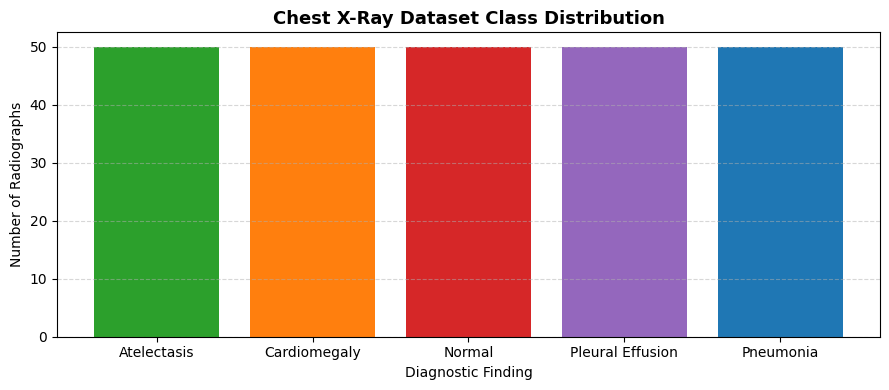

In [2]:
xray_dir = PROJECT_ROOT / "data" / "raw" / "imaging" / "synthetic_xray"
classes = [d.name for d in sorted(xray_dir.iterdir()) if d.is_dir()]
class_counts = {c: len(list((xray_dir / c).glob("*.png"))) for c in classes}

print(f"Chest X-Ray Diagnostic Classes ({len(classes)}):")
for c, count in class_counts.items():
    print(f"  - {c:20s}: {count} images")

plt.figure(figsize=(9, 4))
plt.bar(class_counts.keys(), class_counts.values(), color=["#2ca02c", "#ff7f0e", "#d62728", "#9467bd", "#1f77b4"])
plt.title("Chest X-Ray Dataset Class Distribution", fontsize=13, fontweight="bold")
plt.xlabel("Diagnostic Finding")
plt.ylabel("Number of Radiographs")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 2. Visualizing Radiographs Across All 5 Classes

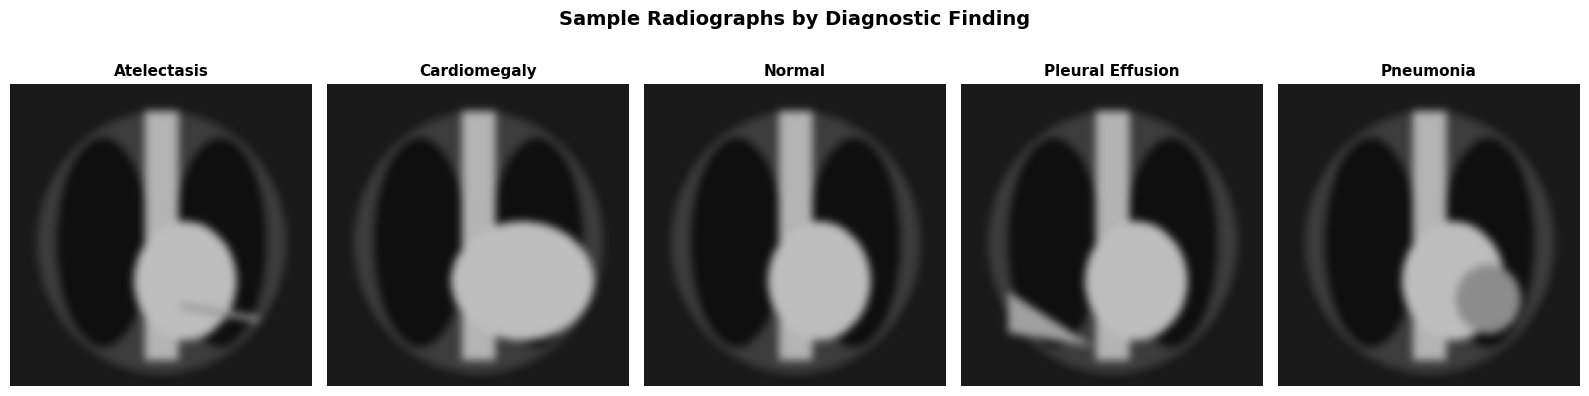

In [3]:
fig, axes = plt.subplots(1, len(classes), figsize=(16, 4))

for i, cls_name in enumerate(classes):
    img_files = list((xray_dir / cls_name).glob("*.png"))
    img = Image.open(img_files[0]).convert("RGB")
    
    ax = axes[i]
    ax.imshow(img, cmap="gray")
    ax.set_title(cls_name, fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("Sample Radiographs by Diagnostic Finding", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 3. Preprocessing Transforms & Pixel Distributions

Preprocessed Tensor Shape: torch.Size([3, 224, 224]) (C, H, W)
Tensor Min/Max/Mean: -1.86 / 1.51 / -0.94


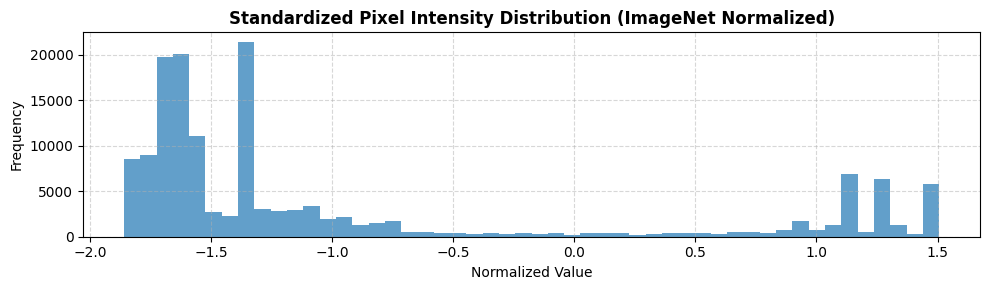

In [4]:
transform_pipeline = get_xray_transforms(image_size=224, is_training=False)

sample_img = Image.open(list((xray_dir / "Cardiomegaly").glob("*.png"))[0]).convert("RGB")
tensor_img = transform_pipeline(sample_img)

print(f"Preprocessed Tensor Shape: {tensor_img.shape} (C, H, W)")
print(f"Tensor Min/Max/Mean: {tensor_img.min():.2f} / {tensor_img.max():.2f} / {tensor_img.mean():.2f}")

plt.figure(figsize=(10, 3))
plt.hist(tensor_img.numpy().flatten(), bins=50, color="#1f77b4", alpha=0.7)
plt.title("Standardized Pixel Intensity Distribution (ImageNet Normalized)", fontsize=12, fontweight="bold")
plt.xlabel("Normalized Value")
plt.ylabel("Frequency")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()